In [1]:
!pip install -q gensim

In [15]:
import gensim.downloader

# model = gensim.downloader.load('word2vec-google-news-300')
model = gensim.downloader.load('glove-wiki-gigaword-50')

print(model["man"])
print(model["king"])

[-0.094386  0.43007  -0.17224  -0.45529   1.6447    0.40335  -0.37263
  0.25071  -0.10588   0.10778  -0.10848   0.15181  -0.65396   0.55054
  0.59591  -0.46278   0.11847   0.64448  -0.70948   0.23947  -0.82905
  1.272     0.033021  0.2935    0.3911   -2.8094   -0.70745   0.4106
  0.3894   -0.2913    2.6124   -0.34576  -0.16832   0.25154   0.31216
  0.31639   0.12539  -0.012646  0.22297  -0.56585  -0.086264  0.62549
 -0.0576    0.29375   0.66005  -0.53115  -0.48233  -0.97925   0.53135
 -0.11725 ]
[ 0.50451   0.68607  -0.59517  -0.022801  0.60046  -0.13498  -0.08813
  0.47377  -0.61798  -0.31012  -0.076666  1.493    -0.034189 -0.98173
  0.68229   0.81722  -0.51874  -0.31503  -0.55809   0.66421   0.1961
 -0.13495  -0.11476  -0.30344   0.41177  -2.223    -1.0756   -1.0783
 -0.34354   0.33505   1.9927   -0.04234  -0.64319   0.71125   0.49159
  0.16754   0.34344  -0.25663  -0.8523    0.1661    0.40102   1.1685
 -1.0137   -0.21585  -0.15155   0.78321  -0.91241  -1.6106   -0.64426
 -0.51042 ]


In [4]:
man_vector = model["man"]
woman_vector = model["woman"]

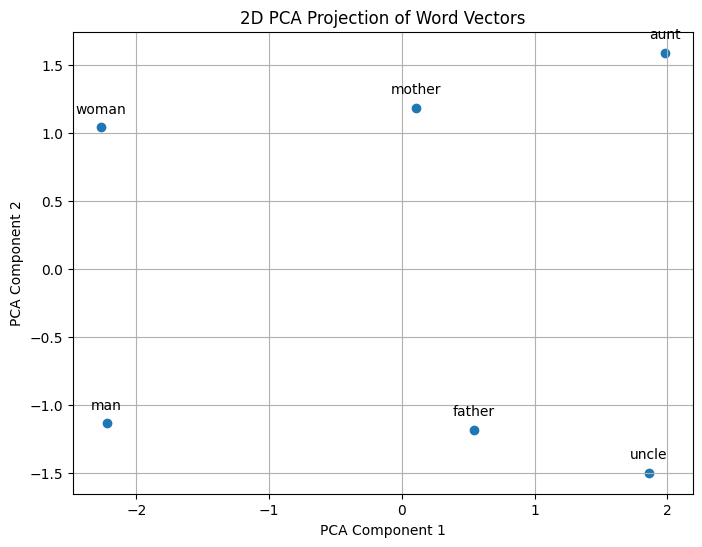

In [18]:
import gensim.downloader
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Load the model (using the same model as before)
# model = gensim.downloader.load('glove-wiki-gigaword-50')

# Hardcoded list of words to display
word_list_str = "uncle, aunt, man, woman, father, mother"
word_list = [word.strip() for word in word_list_str.split(',')]

# Extract vectors for the entered words
vectors = []
labels = []
for word in word_list:
    try:
        vectors.append(model[word])
        labels.append(word)
    except KeyError:
        print(f"Word '{word}' not found in the model vocabulary.")

if not vectors:
    print("No valid words entered to visualize.")
else:
    # Combine the vectors
    combined_vectors = np.vstack(vectors)

    # Apply PCA to reduce the dimensionality to 2
    pca = PCA(n_components=2)
    reduced_vectors = pca.fit_transform(combined_vectors)

    # Create a scatter plot
    plt.figure(figsize=(8, 6))
    plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1])

    # Label the points
    for i, label in enumerate(labels):
        plt.annotate(label, (reduced_vectors[i, 0], reduced_vectors[i, 1]), textcoords="offset points", xytext=(0, 10), ha='center')

    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.title("2D PCA Projection of Word Vectors")
    plt.grid(True)
    plt.show()